# Replicator Dynamics

A hawk–dove population changes composition as actions earn different payoffs. The continuous-time replicator equation predicts how the hawk share evolves.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Population dynamics

An individual meets a random opponent drawn from the current population mix.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

A = np.array([[-1.0, 2.0], [0.0, 1.0]])


def derivative(t, state):
    p = float(state[0])
    w = np.array([p, 1 - p])
    payoffs = A @ w
    return [p * (payoffs[0] - w @ payoffs)]

## Compare with the analytic rest point

Setting the two expected payoffs equal gives an interior hawk share of one half.

Initial 0.05 | Final 0.49987 | Payoff gap 0.00025
Initial 0.22 | Final 0.49996 | Payoff gap 0.00008
Initial 0.68 | Final 0.50002 | Payoff gap 0.00005
Initial 0.94 | Final 0.50011 | Payoff gap 0.00023
Largest final distance from interior rest point: 0.00013


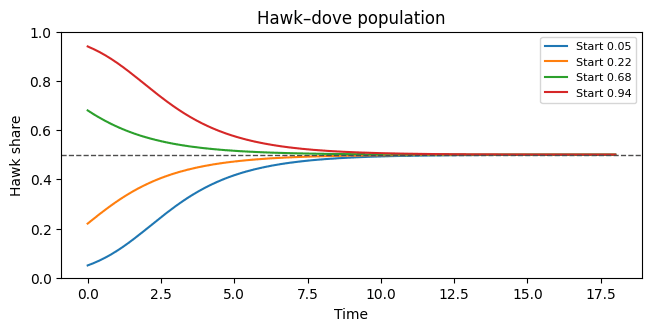

In [3]:
target = 0.5
grid = np.linspace(0, 18, 181)
errors = []
fig, ax = plt.subplots(figsize=(6.4, 3.2), constrained_layout=True)
for start in (0.05, 0.22, 0.68, 0.94):
    result = solve_ivp(derivative, (0, 18), [start], t_eval=grid, rtol=1e-8, atol=1e-10)
    if not result.success:
        raise RuntimeError(result.message)
    p = result.y[0]
    errors.append(abs(p[-1] - target))
    print(
        f"Initial {start:.2f} | Final {p[-1]:.5f} | Payoff gap {abs(np.diff(A@np.array([p[-1],1-p[-1]]))[0]):.5f}"
    )
    ax.plot(grid, p, label=f"Start {start}")
print(f"Largest final distance from interior rest point: {max(errors):.5f}")
ax.axhline(target, color="0.3", linestyle="--", linewidth=1)
ax.set(xlabel="Time", ylabel="Hawk share", title="Hawk–dove population", ylim=(0, 1))
ax.legend(fontsize=8)
plt.show()

## Reading the result

Interior trajectories approach a mixture where neither action earns more. A population starting at an exact pure boundary would stay there under this equation.

## References

[Taylor and Jonker, Evolutionarily Stable Strategies and Game Dynamics (1978)](https://doi.org/10.1016/0025-5564(78)90077-9)

[SciPy, solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)